In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import accuracy_score
from sklearn.model_selection import GridSearchCV

# 1. Carregando os dados encodados
X_train_class = pd.read_csv('../data/processed/X_train_class.csv')
X_test_class = pd.read_csv('../data/processed/X_test_class.csv')
y_train_class = pd.read_csv('../data/processed/y_train_class.csv').squeeze()
y_test_class = pd.read_csv('../data/processed/y_test_class.csv').squeeze()

SEED = 42

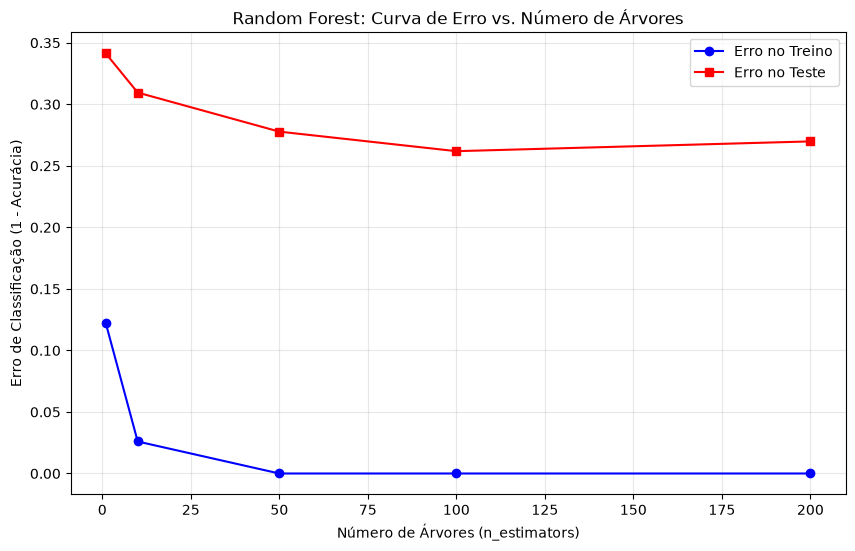

In [2]:
n_arvores = [1, 10, 50, 100, 200]
erros_treino = []
erros_teste = []

for n in n_arvores:
    # Treina Random Forest variando apenas o número de árvores
    rf_temp = RandomForestClassifier(n_estimators=n, random_state=SEED, n_jobs=-1)
    rf_temp.fit(X_train_class, y_train_class)
    
    # Calcula o Erro (1 - Acurácia)
    erro_tr = 1 - accuracy_score(y_train_class, rf_temp.predict(X_train_class))
    erro_te = 1 - accuracy_score(y_test_class, rf_temp.predict(X_test_class))
    
    erros_treino.append(erro_tr)
    erros_teste.append(erro_te)

# Plotando a Curva de Aprendizado do Ensemble
plt.figure(figsize=(10, 6))
plt.plot(n_arvores, erros_treino, marker='o', label='Erro no Treino', color='blue')
plt.plot(n_arvores, erros_teste, marker='s', label='Erro no Teste', color='red')
plt.title('Random Forest: Curva de Erro vs. Número de Árvores')
plt.xlabel('Número de Árvores (n_estimators)')
plt.ylabel('Erro de Classificação (1 - Acurácia)')
plt.legend()
plt.grid(True, alpha=0.3)
os.makedirs('../reports/figures', exist_ok=True)
plt.savefig('../reports/figures/Random Forest: Curva de Erro vs. Número de Árvores.png', bbox_inches='tight', dpi=300)

plt.show()

In [3]:
# Grade para Random Forest (Bagging)
param_grid_rf = {
    'n_estimators': [10, 25 , 50, 75, 100, 125, 150, 175, 200],
    'max_depth': [1, 2, 3, 5, 7, 11, 13],
    'min_samples_leaf': [1, 2, 3, 4]
}

# Grade para Gradient Boosting (Boosting)
param_grid_gb = {
    'n_estimators': [10, 25 , 50, 75, 100, 125, 150, 175, 200],
    'learning_rate': [0.001, 0.01, 0.1],
    'max_depth': [1, 2, 3, 5, 7, 11, 13]
}

# Treinamento Otimizado com Validação Cruzada K-Fold (cv=5)
print("Treinando e otimizando Random Forest...")
grid_rf = GridSearchCV(RandomForestClassifier(random_state=SEED), param_grid_rf, cv=5, scoring='accuracy', n_jobs=-1)
grid_rf.fit(X_train_class, y_train_class)
rf_otimizado = grid_rf.best_estimator_

print("Treinando e otimizando Gradient Boosting...")
grid_gb = GridSearchCV(GradientBoostingClassifier(random_state=SEED), param_grid_gb, cv=5, scoring='accuracy', n_jobs=-1)
grid_gb.fit(X_train_class, y_train_class)
gb_otimizado = grid_gb.best_estimator_

print("\n=== RESULTADOS DOS ENSEMBLES ===")
print(f"Random Forest Melhor CV: {grid_rf.best_score_:.4f} | Acurácia Teste: {accuracy_score(y_test_class, rf_otimizado.predict(X_test_class)):.4f}")
print(f"Gradient Boosting Melhor CV: {grid_gb.best_score_:.4f} | Acurácia Teste: {accuracy_score(y_test_class, gb_otimizado.predict(X_test_class)):.4f}")

print(f"Melhores parâmetros Random Forest: {grid_rf.best_params_}")
print(f"Melhores parâmetros Gradient Boosting: {grid_gb.best_params_}")

Treinando e otimizando Random Forest...
Treinando e otimizando Gradient Boosting...

=== RESULTADOS DOS ENSEMBLES ===
Random Forest Melhor CV: 0.7740 | Acurácia Teste: 0.7143
Gradient Boosting Melhor CV: 0.7840 | Acurácia Teste: 0.7063
Melhores parâmetros Random Forest: {'max_depth': 3, 'min_samples_leaf': 1, 'n_estimators': 75}
Melhores parâmetros Gradient Boosting: {'learning_rate': 0.01, 'max_depth': 5, 'n_estimators': 200}


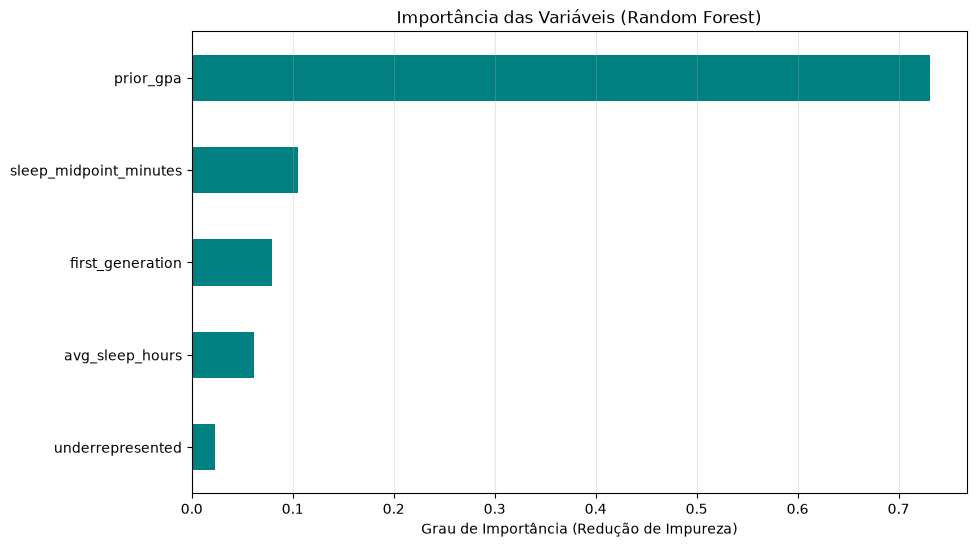

In [4]:
importancias = pd.Series(rf_otimizado.feature_importances_, index=X_train_class.columns)
importancias = importancias.sort_values(ascending=True)

plt.figure(figsize=(10, 6))
importancias.plot(kind='barh', color='teal')
plt.title('Importância das Variáveis (Random Forest)')
plt.xlabel('Grau de Importância (Redução de Impureza)')
plt.grid(axis='x', alpha=0.3)
os.makedirs('../reports/figures', exist_ok=True)
plt.savefig('../reports/figures/Importância das Variáveis (Random Forest).png', bbox_inches='tight', dpi=300)

plt.show()